# Bulgarian powerlifting results: what the meets show

Data: standard-layout results files of the БФСТ national championship rounds, read with `bgopl.analysis.load_frames`.
Everything below is **aggregate**: no names are loaded, so the tables and charts contain no personal data.
Lifters are followed across meets by a short hash of sex and name (`lifter_id`), which is pseudonymous, not anonymous.

Questions:
1. Who competes? (meets, sex, division, weight classes)
2. How strong is the field, and how do the sexes and divisions compare on IPF GL points?
3. Where are lifts missed? (success rate by lift and attempt number)
4. How do lifters choose attempts, and how much do the lifts contribute to the total?
5. Do lifters who compete again improve?
6. How clean is the source data?

Divisions, sexes, classes and every number in the text below are read from the data, so the notebook
keeps working as meets are added. Set `BGOPL_DATA_DIR` to a folder with the normalised files (default `../data`).

In [ ]:
import os
import re

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from bgopl.analysis import load_frames

DATA = os.environ.get("BGOPL_DATA_DIR", "../data")
EQUIPMENT = "classic"  # the analysis is done on one equipment type; change to "equipped" to switch
lifters, attempts, findings = load_frames(DATA)

# Categories come from the data, never from a fixed list.
SEXES = sorted(lifters.sex.dropna().unique())
COLOR = {"F": "#d9730d", "M": "#1f6feb"}
LABEL = {"F": "Women", "M": "Men"}
for _sex in SEXES:
    COLOR.setdefault(_sex, "#7f7f7f")
    LABEL.setdefault(_sex, str(_sex))
LIFT_COLOR = {"squat": "#4c78a8", "bench": "#e45756", "deadlift": "#72b7b2"}


def division_key(label):
    """Juniors, then Open, then masters by number (M1, M2, ...), anything unknown last."""
    fixed = {"SJR": 0, "JR": 1, "Open": 2}
    if label in fixed:
        return (fixed[label], 0, str(label))
    m = re.fullmatch(r"M(\d+)", str(label))
    return (3, int(m[1]), str(label)) if m else (4, 0, str(label))


def class_order(label):
    """Lightest class first, open-ended '+' classes last, odd labels at the very end."""
    try:
        return (label.endswith("+"), float(label.rstrip("+")))
    except ValueError:
        return (True, float("inf"))


def pct(part, whole):
    return f"{100 * part / whole:.0f}%" if whole else "n/a"


DIVISIONS = sorted(lifters.division.dropna().unique(), key=division_key)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True})

classic = lifters[lifters.equipment == EQUIPMENT]
ranked = classic[classic.status == "ranked"]
print(f"{len(lifters)} lifter rows, {len(attempts)} attempts, {lifters.meet.nunique()} meets; "
      f"divisions: {', '.join(DIVISIONS)}")

## 1. Who competes

In [ ]:
overview = (lifters.assign(women=lifters.sex.eq("F"), men=lifters.sex.eq("M"))
            .groupby("meet", observed=True)
            .agg(lifters=("status", "size"),
                 ranked=("status", lambda s: (s == "ranked").sum()),
                 guests=("status", lambda s: (s == "guest").sum()),
                 disqualified=("status", lambda s: (s == "disqualified").sum()),
                 women=("women", "sum"), men=("men", "sum"),
                 equipped=("equipment", lambda s: (s == "equipped").sum())))
overview["women_share_%"] = (100 * overview.women / overview.lifters).round(1)
overview["dq_rate_%"] = (100 * overview.disqualified / overview.lifters).round(1)
overview

,lifters,ranked,guests,disqualified,women,men,equipped,women_share_%,dq_rate_%
meet,,,,,,,,,
2024-11-16,171,167,1,3,34,137,0,19.9,1.8
2026-04-03,128,120,0,8,23,105,0,18.0,6.2
2026-09-19,84,82,1,1,15,69,4,17.9,1.2


In [ ]:
mix = (lifters.groupby(["meet", "division"], observed=True).size().unstack(fill_value=0)
       .reindex(columns=DIVISIONS, fill_value=0))
ax = mix.plot.bar(stacked=True, figsize=(7, 3.6), rot=0, colormap="viridis")
ax.set_ylabel("lifters"); ax.set_xlabel(""); ax.set_title("Lifters by division")
ax.legend(title="division", ncol=3, frameon=False)
plt.show()
mix

In [ ]:
size = (ranked.groupby(["sex", "class_label"]).size().rename("lifters").reset_index())
fig, axes = plt.subplots(1, len(SEXES), figsize=(5 * len(SEXES), 3.4), sharey=True, squeeze=False)
for ax, sex in zip(axes[0], SEXES):
    d = size[size.sex == sex].sort_values("class_label", key=lambda s: s.map(class_order))
    ax.bar(d.class_label, d.lifters, color=COLOR[sex])
    ax.set_title(f"{LABEL[sex]}: ranked lifters per weight class (all meets, {EQUIPMENT})")
    ax.set_xlabel("class, kg")
axes[0][0].set_ylabel("lifters")
plt.tight_layout(); plt.show()

In [ ]:
def biggest(sex, k=2):
    d = size[size.sex == sex].sort_values("lifters", ascending=False).head(k)
    return ", ".join(f"{c} kg ({n})" for c, n in zip(d.class_label, d.lifters))


lines = []
if "F" in SEXES:
    women = overview["women_share_%"]
    small = size[(size.sex == "F") & (size.lifters < 10)]
    text = f"Women are {women.min():.0f} to {women.max():.0f}% of the field at each meet. "
    if len(small):
        text += (f"{len(small)} of their {int((size.sex == 'F').sum())} classes have fewer than 10 "
                 "ranked lifters over all meets; the ")
    else:
        text += "The "
    lines.append(text + f"biggest classes are {biggest('F')}.")
if "M" in SEXES:
    lines.append(f"The men's field is concentrated in {biggest('M', 3)}.")
lines.append("A class ranking only compares lifters within one class, so a points ranking is "
             "needed to compare people across classes.")
junior = mix.reindex(columns=["SJR", "JR"], fill_value=0).sum(axis=1)
none = [str(m) for m in mix.index[junior == 0]]
if none:
    lines.append("The division mix is partly an artefact of how the files are organised: "
                 f"{', '.join(none)} list(s) everyone under Open and veterans, so the SJR and JR "
                 "counts of those meets are zero.")
display(Markdown("\n\n".join(lines)))

## 2. Strength: bodyweight, total and IPF GL points

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.4))
for sex in SEXES:
    d = ranked[ranked.sex == sex]
    ax.scatter(d.bodyweight, d.total, s=14, alpha=.55, color=COLOR[sex], label=LABEL[sex])
ax.set_xlabel("bodyweight, kg"); ax.set_ylabel("total, kg")
ax.set_title(f"Total vs bodyweight (ranked, {EQUIPMENT})"); ax.legend(frameon=False)
plt.show()

In [ ]:
pts = ranked.dropna(subset=["points"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
if len(pts):
    bins = np.arange(5 * np.floor(pts.points.min() / 5), 5 * np.ceil(pts.points.max() / 5) + 5, 5)
    for sex in sorted(SEXES, key=lambda s: -(pts.sex == s).sum()):  # biggest group drawn first
        axes[0].hist(pts[pts.sex == sex].points, bins=bins, alpha=.7, color=COLOR[sex],
                     label=LABEL[sex])
axes[0].set_xlabel("IPF GL points"); axes[0].set_ylabel("lifters"); axes[0].legend(frameon=False)
axes[0].set_title("Distribution of IPF GL points")
order = [d for d in DIVISIONS if d in set(pts.division)]
data = [pts[pts.division == d].points for d in order]
if data:
    axes[1].boxplot(data, tick_labels=[f"{d}\n(n={len(x)})" for d, x in zip(order, data)])
axes[1].set_ylabel("IPF GL points"); axes[1].set_title("Points by division")
plt.tight_layout(); plt.show()
pts.groupby("sex").points.describe().round(1)

In [ ]:
(pts.groupby(["division", "sex"]).points.agg(["count", "median", "max"]).round(1)
 .unstack("sex").dropna(how="all"))

count        median          max       
sex          F      M      F     M      F      M
division                                        
JR        13.0   79.0   59.9  72.6   72.5   98.3
M1         7.0   26.0   65.2  64.4   77.2   82.1
M2         1.0   10.0   47.1  65.9   47.1   81.5
M3         NaN    2.0    NaN  63.2    NaN   68.2
Open      34.0  125.0   65.1  79.5  102.6  105.3
SJR       16.0   52.0   58.6  65.7   89.2   90.1

In [ ]:
lines = []
stats = pts.groupby("sex").points
q = stats.quantile([.25, .5, .75]).unstack()
for sex in SEXES:
    if sex in q.index:
        lines.append(f"{LABEL[sex]}: the middle half score {q.loc[sex, .25]:.0f} to "
                     f"{q.loc[sex, .75]:.0f} points, median {q.loc[sex, .5]:.0f}.")
if {"F", "M"} <= set(q.index):
    gap = q.loc["M", .5] - q.loc["F", .5]
    lines.append(f"The men's median is {abs(gap):.0f} points {'higher' if gap >= 0 else 'lower'} "
                 "than the women's. IPF GL corrects for bodyweight, not for how the two fields are selected, so this gap "
                 "describes who competes here, not strength.")
top = [f"{int((pts[pts.sex == s].points > 90).sum())} of {int((pts.sex == s).sum())} "
       f"{LABEL[s].lower()}" for s in SEXES]
lines.append(f"Lifters above 90 points: {', '.join(top)}.")
by_div = pts.groupby("division").points.agg(["median", "size"])
by_div = by_div[by_div["size"] > 0]
if len(by_div):
    best = by_div["median"].idxmax()
    lines.append(f"{best} has the highest median ({by_div.loc[best, 'median']:.0f}); the divisions "
                 f"differ a lot in size (n from {int(by_div['size'].min())} to "
                 f"{int(by_div['size'].max())}), so compare them with care.")
display(Markdown("\n\n".join(lines)))

## 3. Where lifts are missed

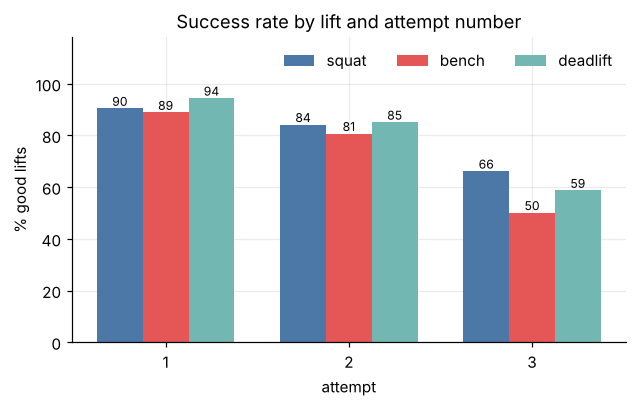

attempts taken,1,2,3
lift,,,
bench,379,374,363
deadlift,378,370,366
squat,378,374,361


In [ ]:
taken = attempts[attempts.equipment == "classic"]
rate = (taken.groupby(["lift", "attempt"]).good.agg(["mean", "size"]).reset_index())
fig, ax = plt.subplots(figsize=(6.5, 3.6))
width = .25
for i, lift in enumerate(["squat", "bench", "deadlift"]):
    d = rate[rate.lift == lift]
    bars = ax.bar(d.attempt + (i - 1) * width, 100 * d["mean"], width, label=lift,
                  color=LIFT_COLOR[lift])
    for b, v in zip(bars, d["mean"]):
        ax.text(b.get_x() + b.get_width() / 2, 100 * v + 1, f"{100 * v:.0f}", ha="center", fontsize=8)
ax.set_xticks([1, 2, 3]); ax.set_xlabel("attempt"); ax.set_ylabel("% good lifts")
ax.set_ylim(0, 118); ax.set_title("Success rate by lift and attempt number")
ax.legend(frameon=False, ncol=3, loc="upper right")
plt.show()
rate.pivot(index="lift", columns="attempt", values="size").rename_axis(columns="attempts taken")

In [ ]:
nine = (classic.merge(attempts[attempts.good].groupby(["meet", "lifter_id"]).size().rename("good9").reset_index(),
                      on=["meet", "lifter_id"], how="left"))
nine["good9"] = nine.good9.fillna(0)
full = attempts.groupby(["meet", "lifter_id"]).size().rename("taken").reset_index()
both = nine.merge(full, on=["meet", "lifter_id"])
both = both[both.taken == 9]
print(f"lifters who took all nine attempts: {len(both)}")
if len(both):
    print(f"  nine good lifts: {(both.good9 == 9).mean():.1%}")
    print(f"  at least seven good: {(both.good9 >= 7).mean():.1%}")
    print(f"  at most five good: {(both.good9 <= 5).mean():.1%}")

In [ ]:
third = rate[rate.attempt == 3].set_index("lift")["mean"]
hardest = third.idxmin()
rest = ", ".join(f"{100 * v:.0f}% in the {k}" for k, v in third.drop(hardest).items())
safest = rate.loc[rate["mean"].idxmax()]
lines = [
    ("Reading the chart: each bar counts only the attempts that were taken, so attempt 3 is "
     "conditional on the lifter getting that far and is not directly comparable with attempt 1."),
    (f"The **{hardest} third attempt is the hardest** ({100 * third.min():.0f}% good, against {rest}); "
     f"the safest attempt of the day is the {safest.lift} attempt {int(safest.attempt)} "
     f"({100 * safest['mean']:.0f}%)."),
    (f"Of the {len(both)} lifters who took all nine attempts, "
     f"{pct((both.good9 == 9).sum(), len(both))} made all nine and "
     f"{pct((both.good9 >= 7).sum(), len(both))} made seven or more."),
]
display(Markdown("\n\n".join(lines)))


## 4. How attempts are chosen, and where the total comes from

In [ ]:
wide = (taken.pivot_table(index=["meet", "lifter_id", "lift"], columns="attempt", values="weight")
        .dropna(subset=[1, 2]).reset_index())
wide["jump2_%"] = 100 * (wide[2] / wide[1] - 1)
wide["jump3_%"] = 100 * (wide[3] / wide[2] - 1)
wide.groupby("lift")[["jump2_%", "jump3_%"]].median().round(1)

attempt,jump2_%,jump3_%
lift,,
bench,6.2,4.0
deadlift,6.5,4.4
squat,6.1,4.3


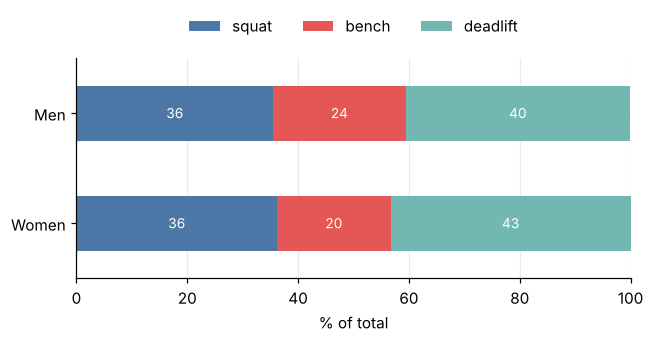

,squat,bench,deadlift
sex,,,
F,36.2,20.5,43.3
M,35.5,23.9,40.5


In [ ]:
sh = ranked.dropna(subset=["best_squat", "best_bench", "best_deadlift", "total"]).copy()
for lift in ["squat", "bench", "deadlift"]:
    sh[lift] = 100 * sh[f"best_{lift}"] / sh.total
share = sh.groupby("sex")[["squat", "bench", "deadlift"]].mean().round(1)
ax = share.rename(index=LABEL).plot.barh(stacked=True, figsize=(6.5, 2.6), color=list(LIFT_COLOR.values()))
ax.set_xlabel("% of total"); ax.set_ylabel(""); ax.set_xlim(0, 100)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.25))
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", label_type="center", color="white", fontsize=9)
plt.show()
share

In [ ]:
jumps = wide.groupby("lift")[["jump2_%", "jump3_%"]].median()
tot = share.rename(index=LABEL)
by_lift = ", ".join(f"{k} {v:.0f}%/{w:.0f}%" for k, (v, w) in jumps.iterrows())
lines = [(f"The median lifter adds {wide['jump2_%'].median():.0f}% to the weight on the second "
          f"attempt and {wide['jump3_%'].median():.0f}% on the third (by lift: {by_lift}).")]
for name, row in tot.iterrows():
    lines.append(f"{name}: the biggest contributor to the total is the {row.idxmax()} "
                 f"({row.max():.0f}%); squat {row['squat']:.0f}%, bench {row['bench']:.0f}%, "
                 f"deadlift {row['deadlift']:.0f}%.")
display(Markdown("\n\n".join(lines)))

## 5. Do lifters who compete again improve?

In [ ]:
one_row = ranked.dropna(subset=["points"]).copy()
count = one_row.groupby(["lifter_id", "meet"], observed=True).size().rename("n").reset_index()
clean = count[count.n == 1][["lifter_id", "meet"]]  # drop names that occur twice in a meet (two people)
one_row = one_row.merge(clean, on=["lifter_id", "meet"])
first_last = (one_row.sort_values("meet").groupby("lifter_id")
              .agg(first=("points", "first"), last=("points", "last"), n=("meet", "nunique")))
rep = first_last[first_last.n >= 2].copy()
rep["change"] = rep["last"] - rep["first"]
print(f"{len(rep)} lifters with at least two {EQUIPMENT} results (name-based identity)")
if len(rep):
    print(f"median change in IPF GL: {rep.change.median():+.1f}; improved: {(rep.change > 0).mean():.0%}")
    lo, hi = 3 * np.floor(rep.change.min() / 3), 3 * np.ceil(rep.change.max() / 3) + 3
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.hist(rep.change, bins=np.arange(lo, hi, 3), color="#4c78a8")
    ax.axvline(0, color="black", lw=1); ax.set_xlabel("IPF GL points, last meet minus first meet")
    ax.set_ylabel("lifters"); ax.set_title(f"Change between a lifter's first and last {EQUIPMENT} result")
    plt.show()

In [ ]:
if len(rep):
    display(Markdown(
        f"{(rep.change > 0).mean():.0%} of the {len(rep)} returning lifters improved, with a median "
        f"change of {rep.change.median():+.1f} IPF GL points. Read it with care: lifters who come back "
        "are not a random sample (people who stop are missing), meets differ in time of year and "
        "peaking, and identity here is sex plus name, so two people with one name would be merged. "
        "The tool for doing this properly needs a birth year or a stable athlete id."))
else:
    display(Markdown("No lifter has two results yet, so there is nothing to compare."))

## 6. How clean is the source data?

In [ ]:
bad = findings[~findings.code.isin(["SUMMARY"]) & (findings.severity != "info")]
table = bad.groupby(["code", "meet"]).size().unstack(fill_value=0)
table

meet,2024-11-16,2026-04-03,2026-09-19
code,,,
ATTEMPT_NOT_PLATE_INCREMENT,0,1,5
DUPLICATE_LIFTER_IN_MEET,2,2,0
POINTS_FOR_UNRANKED,1,1,0
SEX_MISMATCH,1,0,0
TEAM_CLUB_UNKNOWN,0,0,4
TEAM_POINTS_MISMATCH,0,0,3
TEAM_SUM_MISMATCH,0,0,2


Every finding is a question about the source, not a conclusion: the validator reports what disagrees with the file's own arithmetic (weights off the 2.5 kg steps, a disqualified lifter with points, points computed with the wrong sex's formula, team tables that do not add up). The notebook uses the printed values as they are; correcting them is a decision for the federation.